# Import packages

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [2]:
import sys
from pathlib import Path

# Find project root directory
PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "preprocessing").is_dir()
)

# Add project root to Python path
sys.path.insert(0, str(PROJECT_ROOT))

# Import standardization functions
from preprocessing.standardize_types import (
    standardize_types,
    get_type_group
)

# Load data

In [3]:
df_real_1 = pd.read_csv(PROJECT_ROOT / "data" / "export_20261020150603.csv")
df_real_2 = pd.read_csv(PROJECT_ROOT / "data" / "export_20261020160458.csv")

print("Shape of df_real_1:", df_real_1.shape)
print("Shape of df_real_2:", df_real_2.shape)

Shape of df_real_1: (545312, 47)
Shape of df_real_2: (430605, 47)


In [4]:
df_raw = pd.concat([df_real_1, df_real_2], ignore_index=True)
print("Shape of combined df_raw:", df_raw.shape)
df_raw.head()

Shape of combined df_raw: (975917, 47)


,dwellsy_address_id,address1_id,address2_id,data_source_external_id,listing_id,community_id,community_name,company_name,top_down_community_count,top_down_address1_count,address_1,address_2,address_city,address_state,address_zip,address_country,address_type,latitude,longitude,msa_code,msa_name,year_built,bedrooms,full_baths,half_baths,square_feet,rent_amount,listing_deposit,property_listing_status,description,creation_time,deactivation_time,ss_raw_primary_number,ss_raw_street_predirection,ss_raw_street_name,ss_raw_street_suffix,ss_raw_street_postdirection,ss_raw_secondary_designator,ss_raw_secondary_number,ss_raw_default_city_name,ss_raw_state_abbreviation,ss_raw_zipcode,ss_raw_plus4_code,amenities,photos,uru_id,uru_type
0,133822-8163780,133822,8163780.0,1739819,3675156,279577,6211 N Kenmore Ave,Mihail Marinov,28.0,28,6211 N Kenmore Ave,Apt 501,Chicago,IL,60660,US,Apartment,41.994980,-87.656840,16980,"Chicago-Joliet-Naperville, IL-IN-WI MSA",NaN,1,1.0,NaN,800.0,1145.0,0.0,inactive,"HEAT/WATER INCLUDED, PETS WELCOME. PARKING - P...",2021-02-28 15:00:43,2021-04-03 21:02:34,6211,N,Kenmore,Ave,NaN,Apt,501,Chicago,IL,60660,2151,12 Month Lease or Longer; Cable Ready; Cats OK...,https://media.dwellsy.com/prod/c151dd5f3919432...,542230.0,Apartment
1,129521-8112041,129521,8112041.0,3871623,3558998,6069979,Mode Logan Square,Jessica Goodnight,296.0,218,730 N Milwaukee Ave,Apt 807,Chicago,IL,60642,US,Apartment,41.895200,-87.653970,16980,"Chicago-Joliet-Naperville, IL-IN-WI MSA",NaN,1,1.0,NaN,909.0,2500.0,0.0,inactive,River West 1BR + Den! $1000 Bonus! Pets Okay! ...,2021-02-14 07:11:47,2021-03-16 15:16:23,730,N,Milwaukee,Ave,NaN,Apt,807,Chicago,IL,60642,6024,12 Month Lease or Longer; Air Conditioning; Ca...,https://media.dwellsy.com/prod/8c186d97caa2102...,1362919.0,Apartment
2,123813-8066896,123813,8066896.0,14582015,16668829,279329,21st Street Lofts,3L Living,137.0,137,61 E 21st St,Unit 433,Chicago,IL,60616,US,Apartment,41.853916,-87.624672,16980,"Chicago-Joliet-Naperville, IL-IN-WI MSA",2017.0,1,1.0,NaN,572.0,1699.0,NaN,inactive,Discover Modern Living at 21st Street Lofts in...,2025-05-15 13:35:48,2025-05-20 20:05:40,61,E,21st,St,NaN,Unit,433,Chicago,IL,60616,1732,Bike Storage; Cats OK; Deck/Porch/Patio; Eleva...,https://media.dwellsy.com/prod/9f1aec6e910f4f3...,5009610.0,Apartment
3,123813-8066896,123813,8066896.0,14582015,19878436,279329,21st Street Lofts,3L Living,137.0,137,61 E 21st St,Unit 433,Chicago,IL,60616,US,Apartment,41.853916,-87.624672,16980,"Chicago-Joliet-Naperville, IL-IN-WI MSA",2017.0,1,1.0,NaN,572.0,1705.0,NaN,inactive,Discover Modern Living at 21st Street Lofts in...,2026-05-18 15:15:54,2026-06-08 18:47:46,61,E,21st,St,NaN,Unit,433,Chicago,IL,60616,1732,Bike Storage; Cats OK; Deck/Porch/Patio; Eleva...,https://media.dwellsy.com/prod/9f1aec6e910f4f3...,5009610.0,Apartment
4,130630-8121250,130630,8121250.0,10139825,10639335,5764,2420 N Kedzie Blvd,Sam,54.0,54,2420 N Kedzie Blvd,Apt 206,Chicago,IL,60647,US,Apartment,41.925404,-87.708099,16980,"Chicago-Joliet-Naperville, IL-IN-WI MSA",1929.0,0,1.0,NaN,400.0,1450.0,NaN,inactive,"Features hardwood floors, renovated kitchen wi...",2023-06-21 01:50:14,2023-07-11 12:09:18,2420,N,Kedzie,Blvd,NaN,Apt,206,Chicago,IL,60647,5740,Cats OK; Dishwasher; Gas included in rent; Har...,https://media.dwellsy.com/prod/cd5a80b0a1d4a17...,428523.0,Apartment


# Treat multi-value feature

In [5]:
# Split multi-value amenities into binary columns
# Strip whitespace first to avoid creating duplicate columns for values
# such as "Gym" and " Gym".
amenities_dummies = (
    df_raw["amenities"]
    .fillna("")
    .str.split(";")
    .apply(lambda values: ";".join(value.strip() for value in values if value.strip()))
    .str.get_dummies(sep=";")
    .add_prefix("amenity_")
)

# Add binary columns to the original dataframe
df_raw = pd.concat(
    [df_raw, amenities_dummies],
    axis=1
)

# Drop the original multi-value feature
df_raw = df_raw.drop(columns=["amenities"])

print("Number of amenity features:", len(amenities_dummies.columns))
print("Shape after amenities transformation:", df_raw.shape)

Number of amenity features: 260
Shape after amenities transformation: (975917, 306)


In [6]:
df_raw.head()

,dwellsy_address_id,address1_id,address2_id,data_source_external_id,listing_id,community_id,community_name,company_name,top_down_community_count,top_down_address1_count,address_1,address_2,address_city,address_state,address_zip,address_country,address_type,latitude,longitude,msa_code,msa_name,year_built,bedrooms,full_baths,half_baths,square_feet,rent_amount,listing_deposit,property_listing_status,description,creation_time,deactivation_time,ss_raw_primary_number,ss_raw_street_predirection,ss_raw_street_name,ss_raw_street_suffix,ss_raw_street_postdirection,ss_raw_secondary_designator,ss_raw_secondary_number,ss_raw_default_city_name,ss_raw_state_abbreviation,ss_raw_zipcode,ss_raw_plus4_code,photos,uru_id,uru_type,amenity_,amenity_1 Story,amenity_12 Month Lease or Longer,amenity_2 Story,amenity_3 Story,amenity_4plex,amenity_Accent/Track Lighting,amenity_Accessible Bathroom Vanities,amenity_Accessible Climate Controls,amenity_Accessible Kitchen Counters,amenity_Accessible Parking,amenity_Accessible Sink and Range Area,amenity_Air Conditioning,amenity_Alarm/Security System,amenity_Apartment,amenity_Arched Windows,amenity_Attic,amenity_BBQ/Grilling/Picnic Area,amenity_Backsplash,amenity_Barn Doors,amenity_Baseboard Heat,amenity_Basement,amenity_Bathtub,amenity_Bay Windows,amenity_Bike Repair,amenity_Bike Storage,amenity_Billiards/Game Room,amenity_Black Appliances,amenity_Brick Exterior,amenity_Built-in Shelves/Storage,amenity_Business Center,amenity_Cable Ready,amenity_Cable TV/Satellite included in rent,amenity_Car Care,amenity_Carpeted Floors,amenity_Cats OK,amenity_Ceiling Fans,amenity_Central Air Conditioning,amenity_Central Heat,amenity_Certain Dog Breeds Not Allowed,amenity_Chrome/Stainless Steel Fixtures,amenity_Closet Organization,amenity_Clubhouse or Communal Area,amenity_Coffee Bar,amenity_Community Events,amenity_Concierge,amenity_Condominium,amenity_Controlled Access/Gate,amenity_Corner,amenity_Crown Molding/Baseboard Trim,amenity_Cul-de-sac,amenity_Custom Cabinets,amenity_Deck/Porch/Patio,amenity_Decorative Fireplace,amenity_Designer Lighting,amenity_Dishwasher,amenity_Dock,amenity_Dog Run/Park,amenity_Dog Walking,amenity_Door Attendant,amenity_Double Sinks,amenity_Dry Cleaning / Laundry Service,amenity_Duplex,amenity_EV Charging Stations,amenity_Eat-in Kitchen or Breakfast Bar,amenity_Efficient Heating & Cooling,amenity_Efficient Water,amenity_Efficient/Double Pane Windows,amenity_Efficient/Energy Star Appliances,amenity_Electirc Water Heater,amenity_Electric Heat,amenity_Electric Range/Oven,amenity_Electricity NOT included in rent,amenity_Electricity included in rent,amenity_Elevator,amenity_Emergency Maintenance,amenity_End Unit,amenity_European Cabinets,amenity_Exposed Beams,amenity_Exposed Brick,amenity_Extra Storage,amenity_Farmhouse/Apron Sink,amenity_Fence,amenity_Fire/Carbon Monoxide Detectors,amenity_Fishing,amenity_Floor,amenity_Floor to Ceiling Windows,amenity_Freezer,amenity_French Doors,amenity_Front Control Appliances,amenity_Furnished,amenity_Garage or Covered Parking,amenity_Garbage Disposal,amenity_Garden,amenity_Garden Style/Ground Floor,amenity_Gas Heat,amenity_Gas NOT included in rent,amenity_Gas Range/Oven,amenity_Gas Water Heater,amenity_Gas included in rent,amenity_Golf Course,amenity_Grab Bars in Bathroom,amenity_Granite/Quartz/Solid Surface Counters,amenity_Green/LEED Building,amenity_Guest Accomodations,amenity_Guest Parking,amenity_Gym/Fitness Center,amenity_Hardwood Cabinets,amenity_Hardwood or Hardwood Look Floors,amenity_Heat NOT included in rent,amenity_Heat included in rent,amenity_High Rise,amenity_High/Vaulted Ceilings,amenity_Home Health Services,amenity_Hot water included in rent,amenity_Housekeeping Available,amenity_Ice Maker,amenity_Individual Thermostat,amenity_Instant Hot Water,amenity_Intercom,amenity_Internet included in rent,amenity_Keyless Entry,amenity_Kitchen Island,amenity_LED Lighting,amenity_LED Lights,amenity_Lake/Pond/Beach,amenity_Landscaped Exterior,amenity_Large Cl

# Standarize types

In [7]:
# Standardize column types
df_input = standardize_types(df_raw)

# Check the resulting dtypes
print(df_input.dtypes)

# Summary of type groups
df_types = pd.DataFrame({
    "column": df_input.columns,
    "dtype": df_input.dtypes.astype(str).to_numpy(),
    "type_group": [
        get_type_group(dtype)
        for dtype in df_input.dtypes
    ],
})

print("\nType groups:")
print(df_types["type_group"].value_counts())

df_types.head()

dwellsy_address_id                     string
address1_id                             int64
address2_id                           float64
data_source_external_id                 int64
listing_id                              int64
                                       ...   
amenity_Wine Tasting Room               int64
amenity_Wired Home                      int64
amenity_Working Fireplace               int64
amenity_Yard care included in rent      int64
amenity_Yard/Lawn                       int64
Length: 306, dtype: object

Type groups:
type_group
numeric     281
string       23
datetime      2
Name: count, dtype: int64


,column,dtype,type_group
0,dwellsy_address_id,string,string
1,address1_id,int64,numeric
2,address2_id,float64,numeric
3,data_source_external_id,int64,numeric
4,listing_id,int64,numeric


# Identify categorical variables

In [8]:
TARGET = "rent_amount"

# Identify string variables
string_cols = df_types.loc[df_types["type_group"] == "string", "column"].tolist()

# Exclude target if it is included
string_cols = [col for col in string_cols if col != TARGET]

# Multi-value categorical features transformed into binary indicators
amenity_cols = [
    col for col in df_input.columns
    if col.startswith("amenity_")
]

print(f"Number of single-value categorical features: {len(string_cols)}")
print(f"Number of amenity binary features: {len(amenity_cols)}")

Number of single-value categorical features: 23
Number of amenity binary features: 260


# Exploratory Data Analysis

In [9]:
def analyze_string_variables(df, columns, rare_threshold=0.01):

    results = []

    for col in columns:

        series = df[col].dropna()
        counts = series.value_counts(normalize=True)

        results.append({
            "column": col,
            "missing_pct": df[col].isna().mean() * 100,
            "n_unique": series.nunique(),
            "cardinality_ratio": (
                series.nunique() / len(series)
                if len(series) > 0 else np.nan
            ),
            "top_category": (
                counts.index[0] if len(counts) > 0 else None
            ),
            "top_category_pct": (
                counts.iloc[0] * 100 if len(counts) > 0 else np.nan
            ),
            "rare_categories": (
                counts < rare_threshold
            ).sum(),
            "rare_records_pct": (
                counts[counts < rare_threshold].sum() * 100
            ),
        })

    return pd.DataFrame(results)

In [10]:
df_string_eda = analyze_string_variables(df_input, string_cols)
df_string_eda = df_string_eda.sort_values("n_unique", ascending=False)
df_string_eda

,column,missing_pct,n_unique,cardinality_ratio,top_category,top_category_pct,rare_categories,rare_records_pct
11,description,3.033967,312965,0.330722,"Flats 130 is located in NoMa, a rapidly develo...",0.693220,312965,100.000000
0,dwellsy_address_id,0.000000,263691,0.270198,5861298,0.018957,263691,100.000000
21,photos,1.717052,252918,0.263687,https://media.dwellsy.com/prod/3402cac06a2d7dd...,0.794862,252918,100.000000
3,address_1,0.000000,90239,0.092466,720 S Wells St,0.501682,90239,100.000000
1,community_name,0.000000,72418,0.074205,Monroe Street Market,1.095687,72417,98.904313
2,company_name,0.000000,23581,0.024163,Bozzuto Management Company,18.889619,23570,51.869780
12,ss_raw_primary_number,0.000000,15455,0.015836,1201,1.013816,15454,98.986184
14,ss_raw_street_name,0.000000,13668,0.014005,Monroe,1.267218,13664,95.440493
4,address_2,10.362459,10955,0.012523,Apt 2,2.944371,10952,92.147812
18,ss_raw_secondary_number,10.364816,8507,0.009725,2,3.591479,8504,90.783353


In [11]:
def get_category_distribution(df, columns):

    distributions = []

    for col in columns:

        counts = df[col].value_counts(dropna=False)

        temp = pd.DataFrame({
            "column": col,
            "category": counts.index.astype(str),
            "count": counts.values,
            "percentage": counts.values / counts.sum() * 100
        })

        distributions.append(temp)

    return pd.concat(distributions, ignore_index=True)

In [12]:
df_category_distribution = get_category_distribution(df_input, string_cols)
df_category_distribution.head(20)

,column,category,count,percentage
0,dwellsy_address_id,5861298,185,0.018957
1,dwellsy_address_id,7060020-6083378003,157,0.016087
2,dwellsy_address_id,7060013-6083378194,152,0.015575
3,dwellsy_address_id,48301-1553125581,151,0.015473
4,dwellsy_address_id,7060021-6083378069,151,0.015473
5,dwellsy_address_id,7060003-6083378091,140,0.014345
6,dwellsy_address_id,7060013-6082535920,137,0.014038
7,dwellsy_address_id,9051039,136,0.013936
8,dwellsy_address_id,9052108-21326597147,135,0.013833
9,dwellsy_address_id,7059991-6083377762,134,0.013731


# Analyze relationship between categorical variables and the target

In [13]:
def analyze_categorical_target(df, columns, target, min_count=20):

    results = []
    category_details = {}

    for col in columns:

        temp = df[[col, target]].dropna().copy()

        if temp.empty:
            continue

        # Group statistics
        grouped = temp.groupby(col)[target].agg(
            count="count",
            mean="mean",
            median="median",
            std="std"
        )

        category_details[col] = grouped.sort_values(
            "mean", ascending=False
        )

        # Eta squared
        overall_mean = temp[target].mean()

        ## Sum of squares total
        ss_total = (
            (temp[target] - overall_mean) ** 2
        ).sum()

        ## Sum of squares between
        ss_between = (
            grouped["count"] *
            (grouped["mean"] - overall_mean) ** 2
        ).sum()

        ## Eta squared calculation
        eta_squared = (
            ss_between / ss_total
            if ss_total > 0 else np.nan
        )

        # Categories with insufficient observations
        small_categories = (
            grouped["count"] < min_count
        ).sum()

        results.append({
            "column": col,
            "eta_squared": eta_squared,
            "n_categories": len(grouped),
            "small_categories": small_categories,
            "min_category_count": grouped["count"].min(),
            "max_category_count": grouped["count"].max(),
            "target_mean": overall_mean
        })

    df_association = pd.DataFrame(results)

    return (
        df_association.sort_values(
            "eta_squared", ascending=False
        ),
        category_details
    )

In [14]:
df_string_association, category_details = (
    analyze_categorical_target(
        df_input,
        string_cols,
        TARGET,
        min_count=20
    )
)

df_string_association

,column,eta_squared,n_categories,small_categories,min_category_count,max_category_count,target_mean
0,dwellsy_address_id,0.960565,263691,258702,1,185,2126.111241
21,photos,0.957494,252918,246908,1,7624,2132.487671
11,description,0.761306,312965,311080,1,6560,2123.048483
3,address_1,0.701867,90239,84112,1,4896,2126.111241
1,community_name,0.684340,72418,68260,1,10693,2126.111241
2,company_name,0.369168,23581,21867,1,184347,2126.111241
14,ss_raw_street_name,0.342488,13668,11634,1,12367,2126.111241
12,ss_raw_primary_number,0.299093,15455,10186,1,9894,2126.111241
4,address_2,0.289569,10955,8090,1,25757,2084.598237
18,ss_raw_secondary_number,0.238361,8507,6281,1,31417,2084.607892


# Visualize target per categorical variable

In [15]:
def plot_category_target(
    df,
    column,
    target,
    min_count=20,
    top_n=15
):

    temp = df[[column, target]].dropna().copy()

    # Group categories
    counts = temp[column].value_counts()

    valid_categories = counts[
        counts >= min_count
    ].index

    temp = temp[temp[column].isin(valid_categories)]

    # Select categories with highest frequency
    selected = temp[column].value_counts().head(top_n).index

    temp = temp[temp[column].isin(selected)]

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=temp,
        x=column,
        y=target
    )

    plt.xticks(rotation=45, ha="right")
    plt.title(f"{target} distribution by {column}")
    plt.tight_layout()
    plt.show()

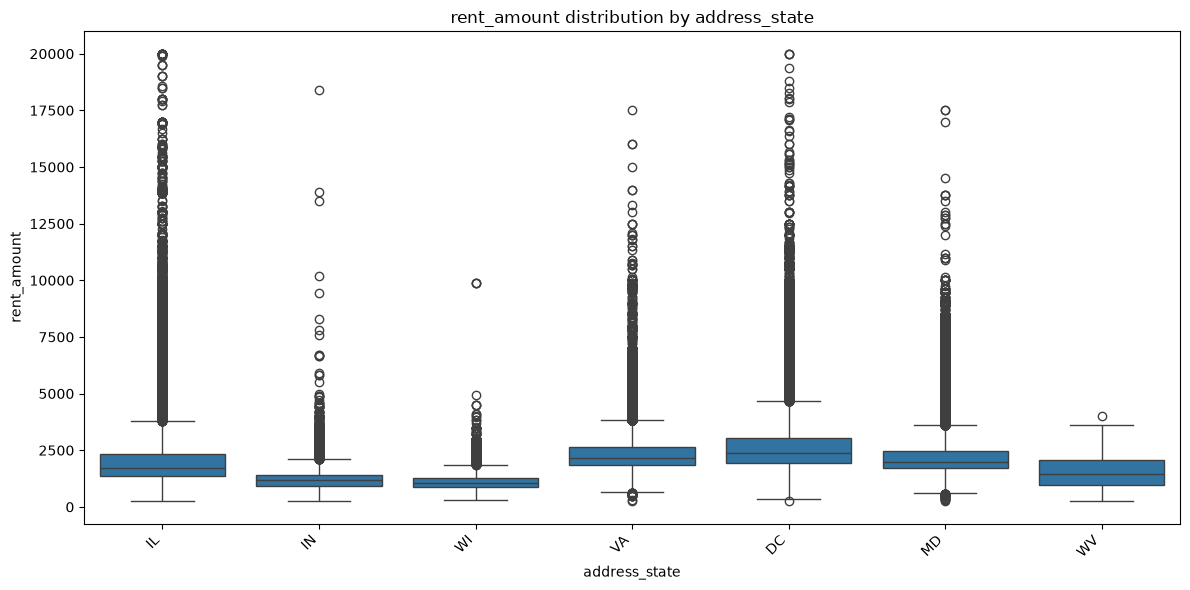

In [16]:
plot_category_target(
    df_input,
    column='address_state',
    target=TARGET
)

# Ranking categorical variables

In [17]:
df_string_ranking = (
    df_string_eda
    .merge(
        df_string_association,
        on="column",
        how="left"
    )
)

df_string_ranking = df_string_ranking.sort_values(
    "eta_squared",
    ascending=False
)

df_string_ranking[
    [
        "column",
        "missing_pct",
        "n_unique",
        "cardinality_ratio",
        "top_category_pct",
        "rare_records_pct",
        "eta_squared",
        "small_categories"
    ]
]

,column,missing_pct,n_unique,cardinality_ratio,top_category_pct,rare_records_pct,eta_squared,small_categories
1,dwellsy_address_id,0.000000,263691,0.270198,0.018957,100.000000,0.960565,258702
2,photos,1.717052,252918,0.263687,0.794862,100.000000,0.957494,246908
0,description,3.033967,312965,0.330722,0.693220,100.000000,0.761306,311080
3,address_1,0.000000,90239,0.092466,0.501682,100.000000,0.701867,84112
4,community_name,0.000000,72418,0.074205,1.095687,98.904313,0.684340,68260
5,company_name,0.000000,23581,0.024163,18.889619,51.869780,0.369168,21867
7,ss_raw_street_name,0.000000,13668,0.014005,1.267218,95.440493,0.342488,11634
6,ss_raw_primary_number,0.000000,15455,0.015836,1.013816,98.986184,0.299093,10186
8,address_2,10.362459,10955,0.012523,2.944371,92.147812,0.289569,8090
9,ss_raw_secondary_number,10.364816,8507,0.009725,3.591479,90.783353,0.238361,6281


# Analyze amenities and their relationship with rent

Analyze each amenity as a binary feature (present = 1, absent = 0)

In [18]:
def analyze_amenity_target(df, columns, target, min_count=20):
    
    results = []

    for col in columns:
        temp = df[[col, target]].dropna().copy()

        if temp.empty:
            continue

        # Ensure the amenity is treated as a binary indicator
        temp[col] = temp[col].astype(int)

        grouped = temp.groupby(col)[target].agg(
            count="count",
            mean="mean",
            median="median",
            std="std"
        )

        # Both groups must be present to compare rent with vs. without amenity
        if 0 not in grouped.index or 1 not in grouped.index:
            continue

        count_0 = grouped.loc[0, "count"]
        count_1 = grouped.loc[1, "count"]

        mean_0 = grouped.loc[0, "mean"]
        mean_1 = grouped.loc[1, "mean"]

        # Eta squared for a binary feature
        overall_mean = temp[target].mean()
        ss_total = ((temp[target] - overall_mean) ** 2).sum()

        ss_between = (
            grouped["count"] *
            (grouped["mean"] - overall_mean) ** 2
        ).sum()

        eta_squared = (
            ss_between / ss_total
            if ss_total > 0 else np.nan
        )

        mean_difference = mean_1 - mean_0
        pct_difference = (
            mean_difference / mean_0 * 100
            if mean_0 != 0 else np.nan
        )

        results.append({
            "amenity": col.replace("amenity_", "", 1),
            "column": col,
            "count_with": count_1,
            "count_without": count_0,
            "presence_pct": temp[col].mean() * 100,
            "mean_rent_with": mean_1,
            "mean_rent_without": mean_0,
            "median_rent_with": grouped.loc[1, "median"],
            "median_rent_without": grouped.loc[0, "median"],
            "mean_rent_difference": mean_difference,
            "mean_rent_difference_pct": pct_difference,
            "eta_squared": eta_squared,
            "meets_min_count": (
                count_1 >= min_count and count_0 >= min_count
            )
        })

    return pd.DataFrame(results)

In [19]:
df_input.shape

(975917, 306)

In [20]:
df_amenity_analysis = analyze_amenity_target(
    df_input,
    amenity_cols,
    TARGET,
    min_count=50
)

# Keep adequately represented amenities for the main ranking
df_amenity_ranking = (
    df_amenity_analysis[
        df_amenity_analysis["meets_min_count"]
    ]
    .sort_values("eta_squared", ascending=False)
    .reset_index(drop=True)
)

df_amenity_ranking.head(20)

,amenity,column,count_with,count_without,presence_pct,mean_rent_with,mean_rent_without,median_rent_with,median_rent_without,mean_rent_difference,mean_rent_difference_pct,eta_squared,meets_min_count
0,Garage or Covered Parking,amenity_Garage or Covered Parking,366922,608995,37.597665,2542.803163,1875.052639,2330.0,1700.0,667.750524,35.612362,0.108819,True
1,Concierge,amenity_Concierge,202337,773580,20.733013,2716.912304,1971.581762,2478.0,1800.0,745.330543,37.803684,0.094966,True
2,Gym/Fitness Center,amenity_Gym/Fitness Center,443027,532890,45.395971,2410.204115,1889.925886,2205.0,1675.0,520.278228,27.529028,0.069795,True
3,Elevator,amenity_Elevator,327631,648286,33.571605,2487.029284,1943.710357,2283.0,1760.0,543.318928,27.952669,0.068478,True
4,Extra Storage,amenity_Extra Storage,298448,677469,30.581289,2507.158179,1958.247181,2289.0,1790.0,548.910998,28.030731,0.066535,True
5,Washer & Dryer On-Site,amenity_Washer & Dryer On-Site,290122,685795,29.728143,1778.636536,2273.108604,1625.0,2100.0,-494.472068,-21.753121,0.053131,True
6,Clubhouse or Communal Area,amenity_Clubhouse or Communal Area,334089,641828,34.233342,2433.052377,1966.339998,2231.0,1750.0,466.712378,23.735080,0.051011,True
7,EV Charging Stations,amenity_EV Charging Stations,82118,893799,8.414445,2842.895858,2060.256480,2552.0,1894.0,782.639377,37.987473,0.049101,True
8,Pet Care/Grooming,amenity_Pet Care/Grooming,91297,884620,9.354996,2789.853866,2057.609839,2501.0,1888.0,732.244027,35.587117,0.047295,True
9,Deck/Porch/Patio,amenity_Deck/Porch/Patio,300146,675771,30.755279,2443.032195,1985.349716,2263.0,1799.0,457.682479,23.052990,0.046403,True


## Visualize the amenities most associated with rent

In [21]:
def plot_top_amenity_rent_differences(
    df_ranking,
    top_n=15,
    ranking_metric="eta_squared"
):
    if df_ranking.empty:
        print("No amenities meet the minimum observation threshold.")
        return

    plot_data = (
        df_ranking
        .nlargest(top_n, ranking_metric)
        .sort_values("mean_rent_difference")
        .copy()
    )

    plt.figure(figsize=(12, max(6, top_n * 0.4)))

    sns.barplot(
        data=plot_data,
        x="mean_rent_difference",
        y="amenity"
    )

    plt.axvline(0, color="black", linewidth=1)
    plt.xlabel("Difference in mean rent (with amenity - without amenity)")
    plt.ylabel("Amenity")
    plt.title(f"Top {len(plot_data)} amenities by {ranking_metric}")
    plt.tight_layout()
    plt.show()

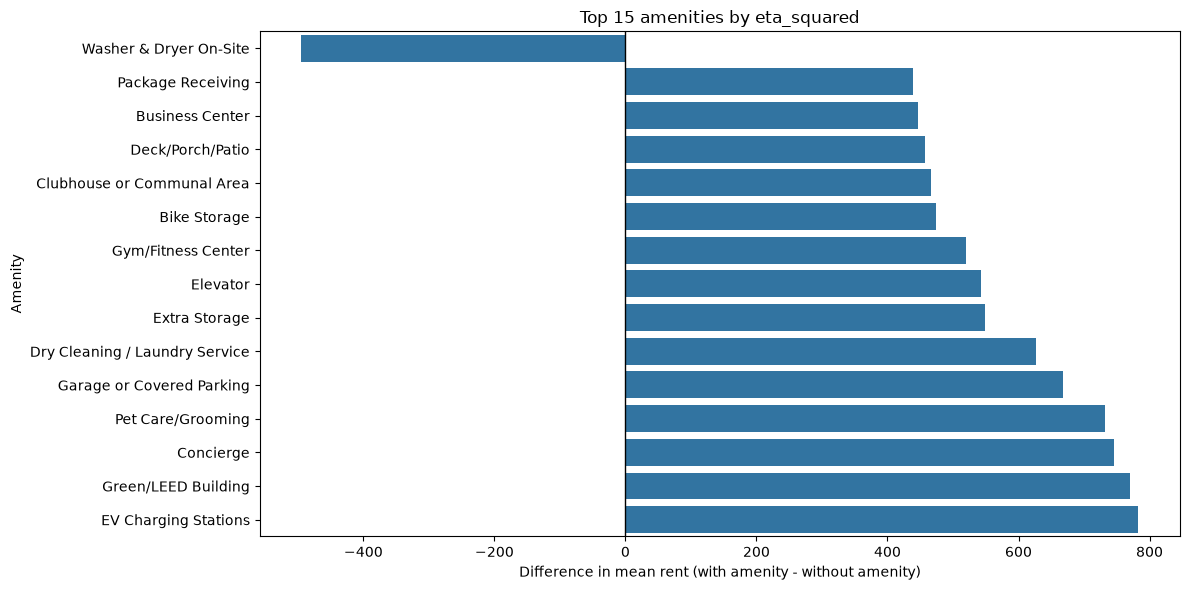

In [22]:
plot_top_amenity_rent_differences(
    df_amenity_ranking,
    top_n=15
)

## Explore individual amenities

In [23]:
# Most frequently listed amenities
df_amenity_ranking.sort_values(
    "presence_pct",
    ascending=False
)[[
    "amenity",
    "presence_pct",
    "count_with",
    "mean_rent_with",
    "mean_rent_without",
    "mean_rent_difference",
    "eta_squared"
]].head(20)

,amenity,presence_pct,count_with,mean_rent_with,mean_rent_without,mean_rent_difference,eta_squared
177,Cats OK,63.005051,614877,2118.029380,2139.875230,-21.845851,0.000116
62,Small Dogs OK,54.629031,533134,2211.066671,2023.820439,187.246232,0.009039
66,Large Dogs OK,52.994568,517183,2207.201924,2034.688494,172.513430,0.007712
58,Pet Restrictions May Apply,52.205977,509487,2220.353982,2023.168781,197.185201,0.010092
2,Gym/Fitness Center,45.395971,443027,2410.204115,1889.925886,520.278228,0.069795
99,Dishwasher,42.449512,414272,2192.716939,2076.982564,115.734374,0.003404
17,Swimming Pool,42.134628,411199,2354.760870,1959.620180,395.140690,0.039598
33,WiFi/High-Speed Internet Available,38.830761,378956,2316.363702,2005.337335,311.026367,0.023901
24,On-Site Management,38.724605,377920,2335.982744,1993.477401,342.505344,0.028955
112,Hardwood or Hardwood Look Floors,38.493130,375661,2067.186531,2162.988366,-95.801834,0.002260


In [24]:
# Amenities associated with the largest average rent premiums
df_amenity_ranking.sort_values(
    "mean_rent_difference",
    ascending=False
)[[
    "amenity",
    "presence_pct",
    "count_with",
    "mean_rent_with",
    "mean_rent_without",
    "mean_rent_difference",
    "mean_rent_difference_pct",
    "eta_squared"
]].head(20)

,amenity,presence_pct,count_with,mean_rent_with,mean_rent_without,mean_rent_difference,mean_rent_difference_pct,eta_squared
74,Mirrored,0.076031,742,4969.942049,2123.947401,2845.994647,133.995533,0.006401
148,Wet Bar,0.011067,108,4283.092593,2125.872512,2157.220081,101.474574,0.000536
39,Wine Storage,0.419400,4093,4119.019790,2117.717772,2001.302018,94.502773,0.017400
155,Solar Panels,0.012399,121,3800.157025,2125.903657,1674.253368,78.754903,0.000361
56,Two Tone Cabinets,0.412125,4022,3758.400547,2119.356326,1639.044220,77.336888,0.011469
106,Massage Therapist,0.127880,1248,3622.273237,2124.195503,1498.077734,70.524475,0.002981
120,Wine Tasting Room,0.069576,679,3601.886598,2125.083747,1476.802851,69.493866,0.001577
53,Soft Close Drawers,0.768303,7498,3400.204988,2116.246549,1283.958439,60.671496,0.013074
160,Gas Water Heater,0.019469,190,3328.842105,2125.877037,1202.965068,56.586766,0.000293
55,Corner,0.883579,8623,3254.301867,2116.053918,1138.247949,53.791065,0.011803


In [25]:
# Amenities with the strongest univariate association with rent
df_amenity_ranking.sort_values(
    "eta_squared",
    ascending=False
)[[
    "amenity",
    "presence_pct",
    "count_with",
    "count_without",
    "mean_rent_difference",
    "mean_rent_difference_pct",
    "eta_squared"
]].head(20)

,amenity,presence_pct,count_with,count_without,mean_rent_difference,mean_rent_difference_pct,eta_squared
0,Garage or Covered Parking,37.597665,366922,608995,667.750524,35.612362,0.108819
1,Concierge,20.733013,202337,773580,745.330543,37.803684,0.094966
2,Gym/Fitness Center,45.395971,443027,532890,520.278228,27.529028,0.069795
3,Elevator,33.571605,327631,648286,543.318928,27.952669,0.068478
4,Extra Storage,30.581289,298448,677469,548.910998,28.030731,0.066535
5,Washer & Dryer On-Site,29.728143,290122,685795,-494.472068,-21.753121,0.053131
6,Clubhouse or Communal Area,34.233342,334089,641828,466.712378,23.735080,0.051011
7,EV Charging Stations,8.414445,82118,893799,782.639377,37.987473,0.049101
8,Pet Care/Grooming,9.354996,91297,884620,732.244027,35.587117,0.047295
9,Deck/Porch/Patio,30.755279,300146,675771,457.682479,23.052990,0.046403
